# Newton Vision Workshop: from a video to a work log

**Archetype AI · Newton**

You call Newton, Archetype AI's physical world model, from Python. Starting from an ordinary video of a worker assembling parts, you produce with the Newton API:

1. a plain-English description of video frames,
2. structured JSON answers a downstream program can use,
3. a PASS / FAIL inspection of a whole video,
4. a second-by-second activity timeline,
5. bounding boxes around objects, drawn from Newton's answer,
6. a before / after comparison,
7. a written shift note, in English and Japanese.

Libraries: `archetypeai` (the official client), `opencv-python` to read frames, `matplotlib` to draw, `pandas` for tables.

| | |
|---|---|
| Time | 90 minutes |
| Level | comfortable with Python; no computer vision background needed |
| Runs on | Google Colab (recommended) or any Python 3.10+ environment |
| Based on | the Newton examples in [archetypeai/agent-skills](https://github.com/archetypeai/agent-skills/tree/main/skills/atai-newton-fusion-model) and the [Developer Quickstart](https://docs.archetypeai.app/introduction/getting-started) |

Run the cells in order. Cells marked **Exercise** are yours to write; each has a hint and a **Checkpoint** that says what a correct result looks like.

## 0. Before you start: your API key

Newton is called with a personal API key. To create one:

1. Open **https://platform.u1.archetypeai.app/console/profile** and log in with the email address your invitation was sent to (reset the temporary password first if you received one).
2. On **Profile & API Keys**, click **Create API key**, name it, and copy the key. It is shown once.
3. The key bills to your organisation: keep it out of repositories and shared documents.

No account yet? Request one at https://www.archetypeai.io/try-newton. Documentation: https://docs.archetypeai.app.

The endpoint is the same for everyone: `https://platform.u1.archetypeai.app`.

## 1. Setup

Install the client and the three helper libraries. On Colab this takes about a minute.

In [1]:
%pip install -q archetypeai opencv-python-headless matplotlib pandas requests

Paste your key between the quotes. If you leave it empty, the cell asks for it with a hidden prompt, so the key never appears in the notebook output.

In [2]:
import os, getpass

ATAI_API_KEY = ""   # <-- paste your API key here, or leave empty to be prompted
ATAI_API_ENDPOINT = "https://platform.u1.archetypeai.app"

if not ATAI_API_KEY:
    ATAI_API_KEY = os.environ.get("ATAI_API_KEY") or getpass.getpass("Archetype AI API key: ")
assert ATAI_API_KEY, "An API key is required (section 0 explains how to get one)."
print("Key loaded:", ATAI_API_KEY[:2] + "..." + ATAI_API_KEY[-4:])

### Sending request to Newton

Every call is one HTTP request: the **model** id, a **query** (the question), an **instruction_prompt** (standing instructions, including output formats), and optionally inline **images** or **file_ids** of uploaded files. The answer is text in `response.response[0]`.

The helper below wraps that request so the rest of the notebook reads `newton("What is in this image?", images=[frame])`.

In [3]:
import json, time, base64, cv2
from archetypeai.api_client import ArchetypeAI

MODEL = "Newton::c2_6_8b_fp8_260424d7a55d5e"
client = ArchetypeAI(ATAI_API_KEY, api_endpoint=ATAI_API_ENDPOINT.rstrip("/") + "/api")

def to_base64_jpeg(frame_bgr, quality=85):
    """An OpenCV frame (BGR uint8) -> base64 JPEG string, the inline image format the API accepts."""
    ok, buf = cv2.imencode(".jpg", frame_bgr, [cv2.IMWRITE_JPEG_QUALITY, quality])
    return base64.b64encode(buf).decode()

def newton(query, instruction="", images=None, as_video=False, fps=1.0, file_ids=None, max_frames=None,
           max_new_tokens=300, retries=2):
    """One call to Newton. Returns (text, seconds).
    images:    a list of OpenCV frames sent inline. as_video=False -> independent images; as_video=True -> frames of one clip
    file_ids:  names of files uploaded with client.files.local.upload(...), e.g. a whole .mp4 (then set max_frames)"""
    body = {"model": MODEL, "query": query, "instruction_prompt": instruction, "file_ids": file_ids or [],
            "max_new_tokens": max_new_tokens, "do_sample": False}        # do_sample=False: greedy, repeatable answers
    if images:
        body["events"] = [{"type": "data.base64_img", "event_data": {"contents": to_base64_jpeg(f)}} for f in images]
        if as_video:   # several frames of ONE video: the API needs to know the clip's timing
            body["multi_image"] = False
            body["query_metadata"] = {"raw_fps": fps, "frames_indices": list(range(len(images))), "total_num_frames": len(images)}
        elif len(images) > 1:
            body["multi_image"] = True   # several independent images (up to 16)
    if max_frames is not None:
        body["max_frames"] = max_frames
    for attempt in range(retries + 1):
        t0 = time.time()
        try:
            payload = client.requests_post(f"{client.api_endpoint}/lens/query", data_payload=json.dumps(body),
                                           additional_headers={"Content-Type": "application/json"})
            return payload["response"]["response"][0], round(time.time() - t0, 1)
        except Exception as e:
            if attempt == retries: raise
            print(f"  retrying after error: {str(e)[:120]}"); time.sleep(3 * (attempt + 1))

text, secs = newton("In one sentence, what can you do with a video?", instruction="You are Newton, a physical world model. Be brief.")
print(f"[{secs}s] {text}")

[0.8s] I can analyze videos to understand actions, objects, and environments, helping you interpret what’s happening in the physical world.


**Checkpoint.** You should see a one-sentence answer and a time under a few seconds. If you get `401`, the key is wrong; `404` means the endpoint URL is wrong (it must be `https://platform.u1.archetypeai.app`, nothing after it).

## 2. The sample data

A 31-second clip of a worker assembling a cap onto a manifold (o-ring, cap, manifold, wrench), recorded by Archetype AI for its examples, plus two frames from it and a second clip of a parcel delivery. Section 10 lets you use your own video.

In [4]:
import urllib.request, pathlib
ASSETS = "https://raw.githubusercontent.com/archetypeai/agent-skills/main/skills/atai-newton-fusion-model/references/sample_assets/"
FILES = {"assembly.mp4": ASSETS + "1_pass_2_pass_3_pass_B.mp4",
         "assembly_before.png": ASSETS + "assembly_before.png",
         "assembly_after.png": ASSETS + "assembly_after.png",
         "delivery.mp4": "https://drive.usercontent.google.com/download?id=1Asy5D47WiDF0mGgP_3krS_GhZFS_c0mv&confirm=t"}
for name, url in FILES.items():
    if not pathlib.Path(name).exists():
        urllib.request.urlretrieve(url, name)
    print(f"{name:22s} {pathlib.Path(name).stat().st_size / 1e6:.1f} MB")

assembly.mp4           7.8 MB
assembly_before.png    0.4 MB
assembly_after.png     0.4 MB
delivery.mp4           8.6 MB


A few OpenCV lines read frames out of a video. `frame_at` returns the frame at a time in seconds; `show` displays one or more frames inline.

{'fps': 30.012, 'frames': 930, 'duration_s': 30.9876, 'size': (640, 480)}


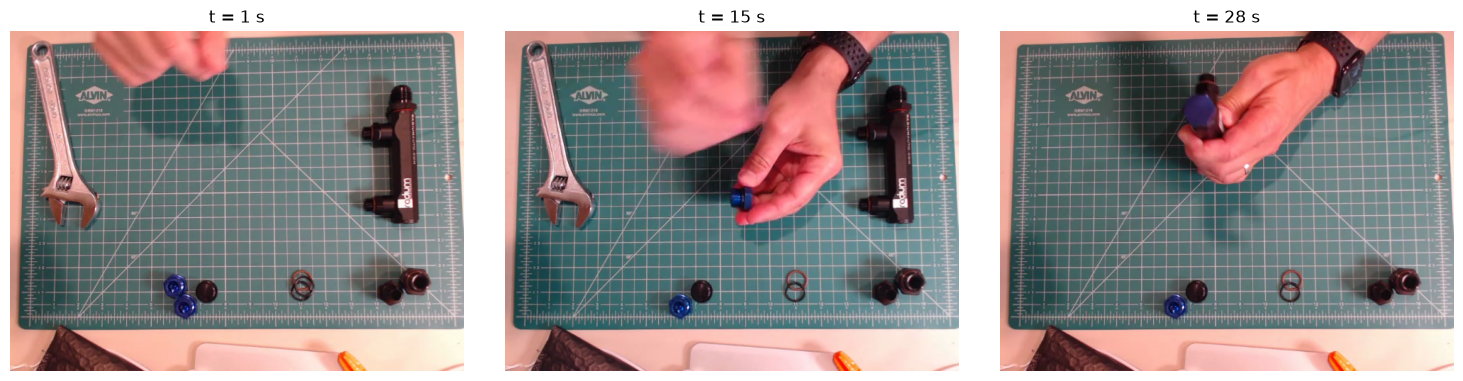

In [5]:
import matplotlib.pyplot as plt

def video_info(path):
    cap = cv2.VideoCapture(path)
    fps = cap.get(cv2.CAP_PROP_FPS); n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)); cap.release()
    return {"fps": round(fps, 4), "frames": n, "duration_s": round(n / fps, 4), "size": (w, h)}

def frame_at(path, seconds):
    """The frame at `seconds` as an OpenCV BGR array."""
    cap = cv2.VideoCapture(path); cap.set(cv2.CAP_PROP_POS_MSEC, seconds * 1000)
    ok, frame = cap.read(); cap.release()
    if not ok: raise ValueError(f"no frame at {seconds}s in {path}")
    return frame

def show(*frames, titles=None, width=5):
    fig, axes = plt.subplots(1, len(frames), figsize=(width * len(frames), width * 0.75))
    for ax, f, t in zip([axes] if len(frames) == 1 else axes, frames, titles or [""] * len(frames)):
        ax.imshow(cv2.cvtColor(f, cv2.COLOR_BGR2RGB)); ax.set_title(t); ax.axis("off")
    plt.tight_layout(); plt.show()

VIDEO = "assembly.mp4"
info = video_info(VIDEO); print(info)
show(frame_at(VIDEO, 1), frame_at(VIDEO, 15), frame_at(VIDEO, 28), titles=["t = 1 s", "t = 15 s", "t = 28 s"])

Play the clip itself, so you know what Newton is about to be asked about.

In [6]:
from IPython.display import Video
Video(VIDEO, embed=True, width=480)

## 3. Lab 1: one image, one question

The simplest call: one frame and one question. The `instruction_prompt` sets the scene; the `query` asks.

In [7]:
frame = frame_at(VIDEO, 15)
text, secs = newton("Describe what is happening in one sentence.", instruction="You are watching a worker at a bench.", images=[frame])
print(f"[{secs}s] {text}")

[1.1s] A worker is assembling or adjusting small mechanical parts on a green cutting mat, using tools like a wrench and handling blue and black components.


### Exercise 1.1

Ask the same frame three different questions of your own, for example *what colour is the cap*, *is any tool on the bench*, *is the worker wearing gloves*. Print each answer with its latency.

In [8]:
for q in ["What colour is the cap the worker is holding?", "List every tool or part you can see on the bench.", "Is the worker wearing a watch?"]:
    text, secs = newton(q, instruction="You are watching a worker at a bench. Answer in one short sentence.", images=[frame])
    print(f"[{secs}s] {q}\n    -> {text}")

[1.0s] What colour is the cap the worker is holding?
    -> The cap the worker is holding is blue.


[1.4s] List every tool or part you can see on the bench.
    -> The worker is assembling or repairing a mechanical component on a green cutting mat.  
Tools and parts visible: adjustable wrench, blue hex bolt, black nuts, O-rings, black cylindrical parts, and a white plastic tool or part.


[0.8s] Is the worker wearing a watch?
    -> Yes, the worker is wearing a black watch on their left wrist.


## 4. Lab 2: structured answers you can compute with

Free text is for people; programs need fields. Put the schema in the `instruction_prompt`, ask for JSON only, and parse the reply. The parser takes the first `{...}` in the text, since answers are sometimes wrapped in markdown fences. In production systems, you can further standardize output format using libraries such as `pydantic`.

In [9]:
import re
def parse_json(text):
    """First JSON object in a model reply, or None."""
    m = re.search(r"\{.*\}", text, re.S)
    try: return json.loads(m.group(0)) if m else None
    except json.JSONDecodeError: return None

SCHEMA = ('Answer ONLY with JSON, no markdown fences: {"parts_visible": ["<part>", ...], "caps_on_bench": <int>, '
          '"hands_busy": true|false, "tool_in_hand": "<wrench|none>", "description": "<= 12 words"}')
text, secs = newton("Describe the frame in the JSON format.", instruction="You are watching a worker at a bench with o-rings, blue caps, black manifolds and a wrench. " + SCHEMA, images=[frame])
answer = parse_json(text)
print(f"[{secs}s] raw: {text}\nparsed: {answer}")
assert answer and "hands_busy" in answer, "expected a JSON object with a hands_busy field"

[1.6s] raw: {
  "parts_visible": ["o-rings", "blue caps", "black manifolds", "wrench"],
  "caps_on_bench": 2,
  "hands_busy": true,
  "tool_in_hand": "none",
  "description": "Worker handles blue cap on green cutting mat with tools nearby."
}
parsed: {'parts_visible': ['o-rings', 'blue caps', 'black manifolds', 'wrench'], 'caps_on_bench': 2, 'hands_busy': True, 'tool_in_hand': 'none', 'description': 'Worker handles blue cap on green cutting mat with tools nearby.'}


### Exercise 2.1

Design a schema for a question that matters on **your** line. Example: `{"ppe_gloves": true|false, "ppe_glasses": true|false, "risk": "low|medium|high", "reason": "..."}`. Run it on the frame at 28 s and print the parsed dictionary.

In [10]:
MY_SCHEMA = ('Answer ONLY with JSON, no markdown fences: {"gloves": true|false, "safety_glasses": true|false, '
             '"sharp_tool_in_use": true|false, "risk": "low|medium|high", "reason": "<= 15 words"}')
text, secs = newton("Assess the frame for safety in the JSON format.", instruction="You are a safety officer reviewing a bench assembly task. " + MY_SCHEMA, images=[frame_at(VIDEO, 28)])
print(f"[{secs}s]", parse_json(text))

[2.5s] {'gloves': False, 'safety_glasses': False, 'sharp_tool_in_use': False, 'risk': 'low', 'reason': 'No hazardous materials or tools visible in frame.'}


**Checkpoint.** `parse_json` returned a dictionary with your fields, not `None`. If it is `None`, print the raw text: the model probably answered in prose, so make the no-fences instruction stronger.

## 5. Lab 3: a whole video in one call

Newton reads video. Upload the file once and reference it by name; the platform samples `max_frames` frames evenly (default 32, maximum 64). The instruction defines three assembly steps and Newton grades each one.

In [11]:
upload = client.files.local.upload(VIDEO)         # once per file; returns the file_id (the file name) used in queries
FILE_ID = upload["file_id"]; print("uploaded as", FILE_ID)

INSPECTION = (
    "You are observing a worker doing an assembly job.\n"
    "Available Components: O-ring (black), Cap (blue), Manifold (black), Wrench\n"
    "Evaluate each step. Answer PASS if the action was performed according to the description, otherwise FAIL.\n"
    "Step 1: attaching / placing / aligning the o-ring to the cap.\n"
    "Step 2: attaching / inserting / aligning the cap to the manifold.\n"
    "Step 3: using a wrench to tighten the cap.\n"
    "Respond in EXACTLY this format:\n"
    "Step 1: PASS or FAIL\nDescription: <1-2 sentences>\n"
    "Step 2: PASS or FAIL\nDescription: <1-2 sentences>\n"
    "Step 3: PASS or FAIL\nDescription: <1-2 sentences>\n"
    "Summary: <2-3 sentences>")
text, secs = newton("Evaluate the assembly steps shown in the attached video.", instruction=INSPECTION, file_ids=[FILE_ID], max_frames=32, max_new_tokens=500)
print(f"[{secs}s]\n{text}")

uploaded as assembly.mp4


[3.3s]
Step 1: PASS
Description: The person correctly places the black O-ring onto the blue cap, ensuring it is seated properly before proceeding.

Step 2: PASS
Description: The blue cap, with the O-ring already in place, is aligned and inserted into the black manifold, fitting securely into its designated slot.

Step 3: PASS
Description: The person uses the wrench to firmly tighten the cap onto the manifold, ensuring a secure connection.

Summary: The assembly process was completed accurately and efficiently, with each step performed correctly: the O-ring was properly seated on the cap, the cap was correctly aligned and inserted into the manifold, and the wrench was used to secure the connection. The final result is a properly assembled component.


### Exercise 3.1: prove it is really watching

Change the description of **Step 3** so that it no longer matches the video (for example, *using a screwdriver to tighten the cap*, or *placing the manifold in a box*) and run the same query. The grade for that step should change to FAIL while the other two stay PASS. Then try `max_frames=8`: faster, but does the reasoning get coarser?

In [12]:
WRONG = INSPECTION.replace("Step 3: using a wrench to tighten the cap.", "Step 3: using a screwdriver to tighten the cap.")
text, secs = newton("Evaluate the assembly steps shown in the attached video.", instruction=WRONG, file_ids=[FILE_ID], max_frames=32, max_new_tokens=500)
print(f"[{secs}s] with a wrong step 3:\n{text}\n")
for budget in (8, 32):
    text, secs = newton("Evaluate the assembly steps shown in the attached video.", instruction=INSPECTION, file_ids=[FILE_ID], max_frames=budget, max_new_tokens=500)
    print(f"--- max_frames={budget} [{secs}s] ---\n{text}\n")

[4.0s] with a wrong step 3:
Step 1: PASS
Description: The person correctly places the black O-ring onto the blue cap, ensuring proper alignment before proceeding.

Step 2: PASS
Description: The cap, with the O-ring already in place, is inserted into the manifold, aligning it properly with the manifold’s threaded opening.

Step 3: FAIL
Description: Instead of using a screwdriver, the person uses a wrench to tighten the cap, which is not the correct tool for this task and may damage the components.

Summary: The first two steps were executed correctly, with proper alignment and insertion. However, the third step incorrectly uses a wrench instead of a screwdriver, which could lead to damage or improper tightening.



--- max_frames=8 [5.4s] ---
Step 1: FAIL
Description: The O-ring is not visibly attached to the cap in the video; instead, the cap is being handled separately.

Step 2: PASS
Description: The cap is inserted into the manifold, aligning it properly for assembly.

Step 3: FAIL
Description: The wrench is not used to tighten the cap; the cap is manually secured.

Summary: The assembly process shows a failure in correctly attaching the O-ring to the cap and in using the wrench to tighten the cap. The cap was successfully inserted into the manifold, but the critical steps involving the O-ring and tightening were not performed as described.



--- max_frames=32 [3.0s] ---
Step 1: PASS
Description: The person correctly places the black O-ring onto the blue cap, ensuring it is seated properly before proceeding.
Step 2: PASS
Description: The cap with the O-ring is aligned and inserted into the manifold, fitting securely into its designated position.
Step 3: PASS
Description: The person uses the wrench to tighten the cap, ensuring it is securely fastened to the manifold.
Summary: The assembly process was executed correctly, with each step performed in sequence and properly aligned. The components were handled with care, and the final tightening ensured a secure fit.



**Checkpoint.** Step 3 reads FAIL with the altered description and PASS with the original. Latency at 8 frames is noticeably lower than at 32, and the grade may change too: with only 8 frames over 31 seconds a short step (the o-ring placement) can fall between the sampled frames and be marked FAIL. Frame budget is a precision knob, not just a speed knob.

## 6. Lab 4: an activity timeline, second by second

One answer per video says whether the job was done. Operations want to know **what happened when**: which step, for how long, in what order. The same pattern runs in production worker-journey solutions:

1. cut the video into windows (here 5 s),
2. sample frames per window with OpenCV (1 per second),
3. send each window as a short clip with a JSON schema and a **vocabulary of steps**,
4. collect the answers in a table and draw them on a time axis.

Each window is one call; a 30 s clip is six calls.

In [13]:
import pandas as pd

STEPS = ["place o-ring on cap", "insert cap into manifold", "tighten cap with wrench", "idle", "other"]
WINDOW_INSTRUCTION = (
    "The frames are consecutive seconds of a worker assembling parts on a bench. Parts: black o-ring, blue cap, black manifold, a wrench. "
    'Answer ONLY with JSON, no markdown fences: {"step": "<one of: ' + " | ".join(STEPS) + '>", '
    '"hands_busy": true|false, "tool_in_hand": "<wrench|none>", "description": "<= 12 words"}')

def window_frames(path, start, length, fps=1.0):
    """Frames of [start, start+length) sampled at `fps` per second, taken from the middle of each second."""
    return [frame_at(path, start + (i + 0.5) / fps) for i in range(int(length * fps))]

def tag_video(path, window_s=5, fps=1.0, instruction=WINDOW_INSTRUCTION):
    rows = []
    duration = video_info(path)["duration_s"]
    for start in range(0, int(duration), window_s):
        frames = window_frames(path, start, min(window_s, duration - start), fps)
        text, secs = newton("What is the worker doing in this window?", instruction=instruction, images=frames, as_video=True, fps=fps, max_new_tokens=120)
        answer = parse_json(text) or {"step": "other", "description": text[:60]}
        rows.append({"start": start, "end": min(start + window_s, duration), "latency_s": secs, **answer})
        print(f"{start:>3}-{int(rows[-1]['end']):<3}s [{secs}s] {answer.get('step'):28s} {answer.get('description', '')}")
    return pd.DataFrame(rows)

log = tag_video(VIDEO)
log

  0-5  s [2.0s] place o-ring on cap          Worker places o-ring onto blue cap on cutting mat.


  5-10 s [3.1s] place o-ring on cap          Worker places o-ring onto blue cap with both hands.


 10-15 s [2.0s] insert cap into manifold     Worker inserts blue cap into black manifold with both hands.


 15-20 s [2.0s] insert cap into manifold     Worker inserts blue cap into black manifold component.


 20-25 s [2.1s] insert cap into manifold     Worker inserts blue cap into black manifold with both hands.


 25-30 s [2.1s] tighten cap with wrench      Worker tightens blue cap using wrench on green cutting mat.


,start,end,latency_s,step,hands_busy,tool_in_hand,description
0,0,5,2.0,place o-ring on cap,True,none,Worker places o-ring onto blue cap on cutting ...
1,5,10,3.1,place o-ring on cap,True,none,Worker places o-ring onto blue cap with both h...
2,10,15,2.0,insert cap into manifold,True,none,Worker inserts blue cap into black manifold wi...
3,15,20,2.0,insert cap into manifold,True,none,Worker inserts blue cap into black manifold co...
4,20,25,2.1,insert cap into manifold,True,none,Worker inserts blue cap into black manifold wi...
5,25,30,2.1,tighten cap with wrench,True,wrench,Worker tightens blue cap using wrench on green...


Now draw it. One horizontal bar per window, coloured by step: the clip's story at a glance.

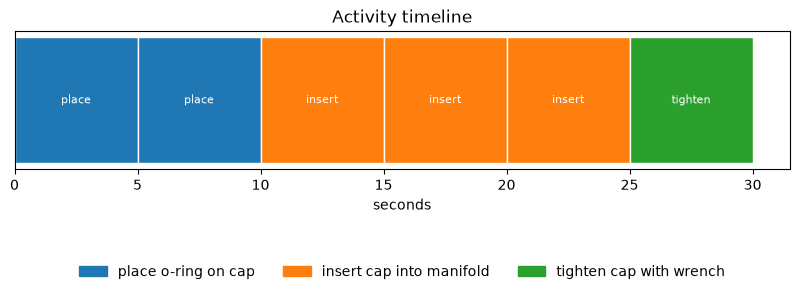

Time per step (s):
step
insert cap into manifold    15
place o-ring on cap         10
tighten cap with wrench      5
dtype: int64


In [14]:
def plot_timeline(log, steps=STEPS, title="Activity timeline"):
    colours = dict(zip(steps, plt.cm.tab10.colors))
    fig, ax = plt.subplots(figsize=(10, 1.8))
    for _, r in log.iterrows():
        ax.barh(0, r.end - r.start, left=r.start, color=colours.get(r.step, "grey"), edgecolor="white")
        ax.text((r.start + r.end) / 2, 0, r.step.split(" ")[0], ha="center", va="center", fontsize=8, color="white")
    ax.set_yticks([]); ax.set_xlabel("seconds"); ax.set_title(title)
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for s, c in colours.items() if s in set(log.step)],
              labels=[s for s in colours if s in set(log.step)], loc="upper center", bbox_to_anchor=(0.5, -0.6), ncol=5, frameon=False)
    plt.show()

plot_timeline(log)
print("Time per step (s):"); print((log.end - log.start).groupby(log.step).sum().sort_values(ascending=False))

### Exercise 4.1: sharpen the timeline

Re-run the tagging with **3-second windows** and compare the two timelines. Then add one field to the schema (for example `"left_hand": "<what it holds>"`) and check it appears in the table.

  0-3  s [1.8s] place o-ring on cap          Worker places o-ring onto blue cap for assembly.


  3-6  s [1.7s] place o-ring on cap          Worker places black o-ring onto blue cap for assembly.


  6-9  s [1.9s] place o-ring on cap          Worker places o-ring onto blue cap with both hands.


  9-12 s [2.4s] place o-ring on cap          Worker places o-ring onto blue cap in hands.


 12-15 s [1.7s] insert cap into manifold     Worker inserts blue cap into black manifold component.


 15-18 s [1.8s] insert cap into manifold     Worker inserts blue cap into black manifold with both hands.


 18-21 s [1.6s] insert cap into manifold     Worker inserts blue cap into black manifold with both hands.


 21-24 s [1.8s] insert cap into manifold     Worker inserts blue cap into black manifold with both hands.


 24-27 s [1.8s] tighten cap with wrench      Worker tightens blue cap using wrench on green cutting mat.


 27-30 s [1.7s] tighten cap with wrench      Worker tightens blue cap using wrench on green cutting mat.


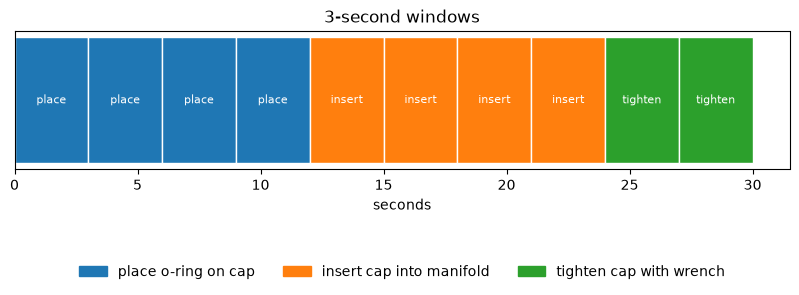

  0-5  s [2.1s] place o-ring on cap          Worker places o-ring onto blue cap for assembly.


  5-10 s [2.1s] place o-ring on cap          Worker places o-ring onto blue cap for assembly.


 10-15 s [2.2s] place o-ring on cap          Worker places o-ring onto blue cap with both hands.


 15-20 s [2.8s] insert cap into manifold     Worker inserts blue cap into black manifold on cutting mat.


 20-25 s [2.2s] insert cap into manifold     Worker inserts cap into manifold while holding it with both hands.


 25-30 s [2.4s] tighten cap with wrench      Worker tightens blue cap using adjustable wrench on manifold.


,start,end,step,left_hand
0,0,5,place o-ring on cap,blue cap
1,5,10,place o-ring on cap,blue cap
2,10,15,place o-ring on cap,blue cap
3,15,20,insert cap into manifold,holds black manifold
4,20,25,insert cap into manifold,black manifold
5,25,30,tighten cap with wrench,holds wrench handle


In [15]:
log3 = tag_video(VIDEO, window_s=3)
plot_timeline(log3, title="3-second windows")
EXTRA = WINDOW_INSTRUCTION.replace('"description":', '"left_hand": "<what the left hand holds>", "description":')
log_extra = tag_video(VIDEO, window_s=5, instruction=EXTRA)
log_extra[["start", "end", "step", "left_hand"]]

**Checkpoint.** The 3-second timeline shows the same three phases with sharper boundaries, and the new column is filled in every row.

## 7. Lab 5: Newton finds objects

Ask for coordinates and Newton returns them: one line per object, `name: [x1, y1, x2, y2]` on a 0 to 1000 scale independent of image size. Scale to pixels and OpenCV draws the boxes. Locating and counting is one more question to the same model.

[3.0s]
hand: [0, 114, 300, 568]
wrench: [101, 189, 453, 413]
cap: [357, 777, 405, 845], [407, 726, 458, 796], [817, 730, 868, 801], [864, 696, 928, 777]
manifold: [407, 128, 526, 312]


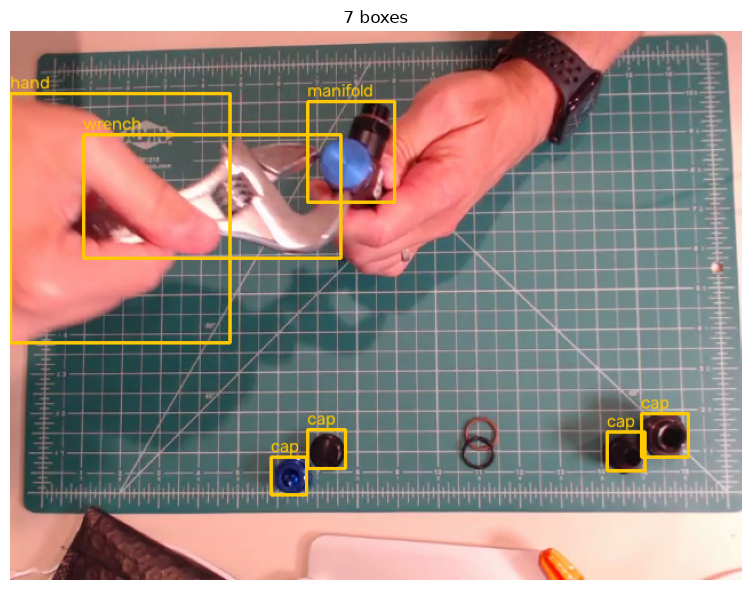

In [16]:
DETECT = ("Detect all the occurrences of the following objects in the image. For each detection, output a single line "
          "consisting of the class name, a colon, and the bounding box in the normalized range (0-1000) as [x1, y1, x2, y2].")

def detect(frame, objects):
    """-> list of (name, x1, y1, x2, y2) in pixels."""
    text, secs = newton("Objects: " + ", ".join(objects), instruction=DETECT, images=[frame], max_new_tokens=300)
    h, w = frame.shape[:2]; boxes = []
    for line in text.splitlines():
        if ":" not in line: continue
        name, rest = line.split(":", 1)
        for x1, y1, x2, y2 in re.findall(r"\[(\d+),\s*(\d+),\s*(\d+),\s*(\d+)\]", rest):
            boxes.append((name.strip(), int(x1) * w // 1000, int(y1) * h // 1000, int(x2) * w // 1000, int(y2) * h // 1000))
    return boxes, text, secs

def draw(frame, boxes):
    out = frame.copy()
    for name, x1, y1, x2, y2 in boxes:
        cv2.rectangle(out, (x1, y1), (x2, y2), (0, 200, 255), 2)
        cv2.putText(out, name, (x1, max(12, y1 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 200, 255), 1)
    return out

frame = frame_at(VIDEO, 28.5)
boxes, raw, secs = detect(frame, ["hand", "wrench", "cap", "manifold"])
print(f"[{secs}s]\n{raw}")
show(draw(frame, boxes), titles=[f"{len(boxes)} boxes"], width=8)

### Exercise 5.1: count the caps

Run `detect` on the frame at 1 s asking for `cap` and `o-ring` only, draw the result, and print how many of each were found. Does the count agree with what you see?

[1.3s] Counter({'cap': 1, 'o-ring': 1})


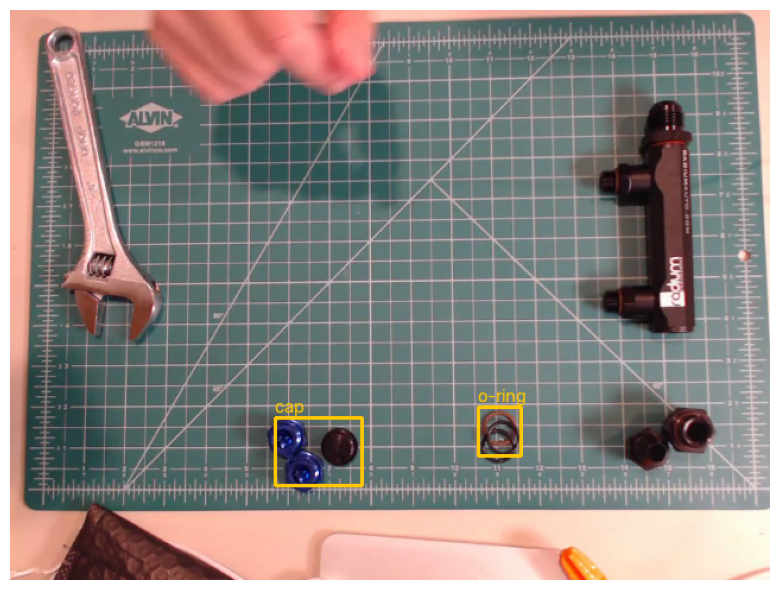

In [17]:
f1 = frame_at(VIDEO, 1)
boxes, raw, secs = detect(f1, ["cap", "o-ring"])
from collections import Counter
print(f"[{secs}s]", Counter(b[0] for b in boxes))
show(draw(f1, boxes), width=8)

**Checkpoint.** Boxes land on the caps and rings, and the counts match what you see.

## 8. Lab 6: before and after

Several **independent** images in one call (up to 16) let Newton compare states: a shelf before and after a shift, a machine before and after maintenance. Here, the bench before and after the assembly.

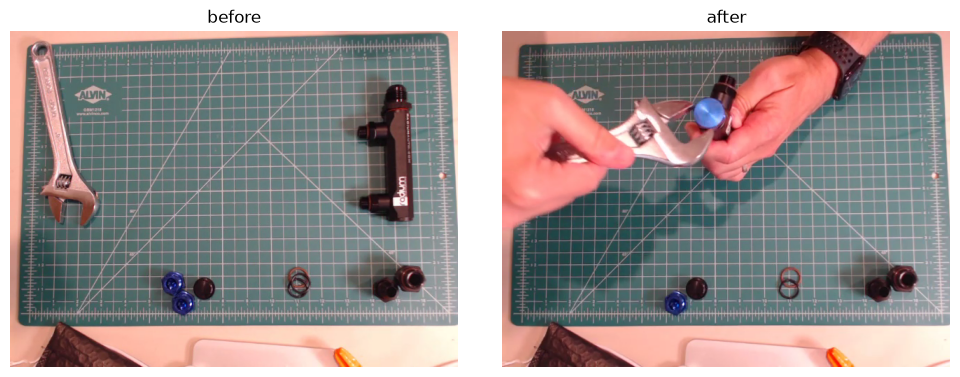

[2.6s]
- A blue cap was added to the black cylindrical component.
- The adjustable wrench is now actively gripping the component, not resting on the mat.
- The blue cap that was on the mat is now on the component.


In [18]:
before, after = cv2.imread("assembly_before.png"), cv2.imread("assembly_after.png")
show(before, after, titles=["before", "after"])
text, secs = newton("Image 1 shows BEFORE the task, image 2 shows AFTER. What changed? Answer in three short bullets.",
                    instruction="You compare two photos of the same workbench.", images=[before, after])
print(f"[{secs}s]\n{text}")

## 9. Lab 7: from observations to a shift note

The timeline table is the fact base. Give it to Newton as **text only** and ask for the note a supervisor would read; then a second call translates it into Japanese.

In [19]:
facts = "\n".join(f"{int(r.start)}-{int(r.end)} s: step={r.step}; tool={r.tool_in_hand}; {r.description}" for _, r in log.iterrows())
NOTE = ("You write a short work note for a line supervisor from per-window observations of one assembly job. "
        "Three sentences, plain English, no bullet points, facts only, include the timings.\n\nObservations:\n" + facts)
note, secs = newton("Write the work note.", instruction=NOTE, max_new_tokens=200)
print(f"[{secs}s]\n{note}")

ja, secs = newton(note, instruction="Translate the following work note into natural, polite business Japanese (です・ます調) for a line supervisor. Keep every number. Output only the Japanese text.", max_new_tokens=300)
print(f"\n[{secs}s]\n{ja}")

[1.2s]
From 0 to 5 seconds, the worker places the o-ring onto the blue cap using no tool. From 5 to 30 seconds, the worker inserts the cap into the black manifold and tightens it with a wrench, completing the task in 30 seconds total.



[2.0s]
作業ノートを自然で丁寧なビジネス日本語（です・ます調）に翻訳いたします。数字はすべて保持します。

0秒から5秒まで、作業者は工具を使わずにOリングを青いキャップに装着します。5秒から30秒まで、作業者はキャップを黒いマニフォールドに挿入し、レンチで締め込みます。総作業時間は30秒です。


### Exercise 7.1

Make the note useful: ask for a fourth sentence that flags anything unusual (a long idle window, a step out of order, a tool used when it should not be). Hint: add the rule to the instruction, not the query.

In [20]:
NOTE2 = NOTE.replace("Three sentences,", "Four sentences, the fourth flagging anything unusual (idle time, a step out of order, a wrong tool) or stating that nothing was unusual;")
note2, secs = newton("Write the work note.", instruction=NOTE2, max_new_tokens=250)
print(f"[{secs}s]\n{note2}")

[2.3s]
Worker completed the assembly of one unit within 30 seconds, starting at 0s. The o-ring was placed on the blue cap between 0–10s using both hands, no tool required. The cap was inserted into the black manifold between 10–25s, again using both hands and no tool. The cap was tightened with a wrench between 25–30s. No unusual activity observed.


## 10. Lab 8: your own video

Everything above depends on three things: a video, a vocabulary of steps, and a schema. Upload your own clip (a phone video of any manual task, under about a minute), name the steps, and run the same pipeline. On Colab the next cell opens a file picker; elsewhere set `MY_VIDEO` to a path.

delivery.mp4 {'fps': 24.0, 'frames': 728, 'duration_s': 30.3333, 'size': (1920, 1080)}


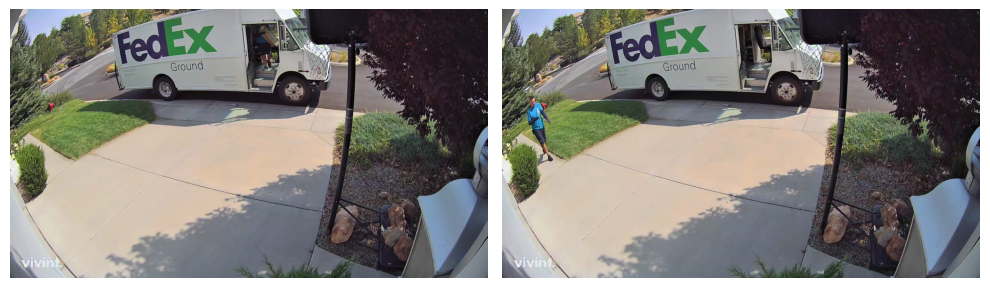

In [21]:
try:
    from google.colab import files            # Colab only
    uploaded = files.upload()
    MY_VIDEO = next(iter(uploaded))
except ImportError:
    MY_VIDEO = "delivery.mp4"                 # fallback outside Colab: the second sample clip
print(MY_VIDEO, video_info(MY_VIDEO))
show(frame_at(MY_VIDEO, 1), frame_at(MY_VIDEO, video_info(MY_VIDEO)["duration_s"] / 2))

### Exercise 8.1: describe your task to Newton

1. Write `MY_STEPS`, the vocabulary of actions in your clip (4 to 6 short phrases plus `idle` and `other`).
2. Build `MY_INSTRUCTION` the same way as `WINDOW_INSTRUCTION`: one sentence of context, then the JSON schema with your steps.
3. Run `tag_video(MY_VIDEO, window_s=5, instruction=MY_INSTRUCTION)` and plot the timeline with `plot_timeline(df, steps=MY_STEPS)`.
4. Write the work note for it.

  0-5  s [2.9s] carry a package toward the house FedEx courier carries package from truck toward house.


  5-10 s [3.7s] carry a package toward the house A FedEx worker carries a package toward the house.


 10-15 s [3.2s] no one in view               FedEx truck parked, no courier visible in frame.


 15-20 s [3.3s] board the truck              Courier boards FedEx truck after walking up driveway.


 20-25 s [3.1s] no one in view               FedEx truck parked with driver inside, no one visible outside.


 25-30 s [4.3s] truck drives away            FedEx truck departs driveway, no courier in view.


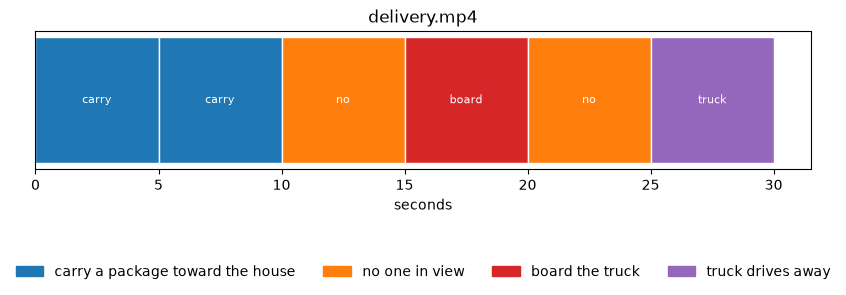

[2.0s]
Between 0–5 seconds, a FedEx courier carries a package from the truck toward the house. From 5–10 seconds, another FedEx worker is seen carrying a package toward the house, while the truck remains parked and unoccupied from 10–20 seconds. At 15–20 seconds, a courier boards the truck after walking up the driveway; the truck then departs the driveway at 25–30 seconds, with no courier visible outside during either departure or prior parking periods.


In [22]:
MY_STEPS = ["carry a package toward the house", "no one in view", "walk back to the truck", "board the truck", "truck drives away", "other"]
MY_INSTRUCTION = ("The frames are consecutive seconds from a house camera that faces the driveway and a parked delivery truck. "
                  'Answer ONLY with JSON, no markdown fences: {"step": "<one of: ' + " | ".join(MY_STEPS) + '>", '
                  '"courier_visible": true|false, "carrying_package": true|false, "description": "<= 12 words"}')
my_log = tag_video(MY_VIDEO, window_s=5, instruction=MY_INSTRUCTION)
plot_timeline(my_log, steps=MY_STEPS, title=MY_VIDEO)
my_facts = "\n".join(f"{int(r.start)}-{int(r.end)} s: step={r.step}; {r.description}" for _, r in my_log.iterrows())
note, secs = newton("Write the note.", instruction="You write a three-sentence factual note from these per-window observations, with timings.\n\n" + my_facts, max_new_tokens=200)
print(f"[{secs}s]\n{note}")

## 11. What you built, and where it goes next

| You did | The API feature | Where it is used in production |
|---|---|---|
| Described a frame | one `data.base64_img` event | monitoring dashboards, alert text |
| Got JSON back | the schema in `instruction_prompt` | anything downstream that computes |
| Graded a whole video | `file_ids` + `max_frames` | task verification, SOP compliance |
| Built a timeline | windows of frames with `query_metadata` | worker journey, cycle-time studies, line balancing |
| Drew boxes | a detection instruction on the 0 to 1000 grid | counting, zone occupancy |
| Compared images | `multi_image: true` | before / after audits |
| Wrote the note | text-only query | daily shift summaries, bilingual reporting |

Before scaling up:

- **Latency.** Text under a second; one image 1 to 3 s; a 32-frame video 3 to 6 s. Windows are independent calls, so a thread pool of 4 brings a 10-minute recording to a few minutes.
- **Limits.** 16 images per multi-image call, 64 frames per video call; `file_id` is the file name. Several frames without `query_metadata` or `multi_image` fail with `400 query_failed`.
- **Repeatability.** `do_sample: false` gives greedy decoding; borderline judgements can still vary, so aggregate several windows rather than trusting one.
- **Resolution.** Newton reads images in 32-pixel cells. A hand a few pixels wide in a wide shot is invisible; crop or film close to what matters.
- **Documentation.** https://docs.archetypeai.app and the examples at https://github.com/archetypeai.

## Appendix: the request, field by field

```
POST https://platform.u1.archetypeai.app/api/lens/query
Authorization: Bearer <API key>
Content-Type: application/json

{
  "model": "Newton::c2_6_8b_fp8_260424d7a55d5e",
  "query": "the question",
  "instruction_prompt": "standing instructions; put output formats here",
  "file_ids": ["assembly.mp4"],            # files uploaded with client.files.local.upload(); optional
  "max_frames": 32,                        # for a video file_id: frames sampled server-side (default 32, max 64)
  "events": [{"type": "data.base64_img", "event_data": {"contents": "<base64 JPEG or PNG>"}}],
  "multi_image": false,                    # true: independent images (<= 16); false: frames of one clip
  "query_metadata": {"raw_fps": 1.0, "frames_indices": [0, 1, 2], "total_num_frames": 3},   # required with multi_image=false
  "max_new_tokens": 300,
  "do_sample": false                       # greedy decoding; omit for sampled answers
}
```

Response: `{"status": "completed", "query_id": "...", "inference_time_sec": 0.4, "response": {"response": ["<model output>"]}}`

Common errors: `401` wrong key · `404` wrong endpoint (no `/v0.5`, no trailing path) · `400 invalid_model_version` the model id is incomplete · `400 query_failed` several frames sent without `query_metadata` · `400 unsupported_file_type` a file UID (`fil_...`) was passed instead of the file name.